# Results Plots — Risk-Aware Dynamic A* for Satellite Anomaly Recovery

Loads the results CSV from `experiments/run_experiment.py` and generates comparison plots.

**Run the pipeline first:**
```bash
python experiments/generate_nominal_data.py --n-trajectories 500 --steps-per-traj 200
python experiments/train_scorer.py --n-estimators 200
python experiments/run_experiment.py --sweep --seeds 10 --scorer experiments/scorers/isolation_forest.joblib
python experiments/run_experiment.py --scenario single_thermal --algorithm astar --variant H2 --sweep-lambda --seeds 5 --scorer experiments/scorers/isolation_forest.joblib
```


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..'))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'legend.fontsize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})
sns.set_style('whitegrid')
print('Imports OK')

Imports OK


## 1  Load results

In [2]:
RESULTS_PATH = Path('../experiments/results/results.csv')
assert RESULTS_PATH.exists(), f'Results file not found: {RESULTS_PATH}'

df = pd.read_csv(RESULTS_PATH)

ALGO_LABELS = {
    'astar': 'A*', 'idastar': 'IDA*', 'rbfs': 'RBFS',
    'hill_climbing': 'Hill Climb', 'simulated_annealing': 'Sim. Ann.',
}
SCENARIO_LABELS = {
    'single_thermal': 'Thermal Runaway', 'single_power': 'Battery Degradation',
    'single_load': 'High Bus Load',      'cascade': 'Cascade (T+P)',
    'single_thermal_sun': 'Thermal (Sun)', 'single_power_sun': 'Battery (Sun)',
}
VARIANT_COLORS = {
    'H0': '#888888', 'H1': '#4C72B0', 'H2': '#DD8452', 'H3': '#55A868', 'H4': '#C44E52',
}

df['algo_label']     = df['algorithm'].map(ALGO_LABELS).fillna(df['algorithm'])
df['scenario_label'] = df['scenario'].map(SCENARIO_LABELS).fillna(df['scenario'])

print(f'Loaded {len(df):,} rows')
print('Scenarios :', df.scenario.unique().tolist())
print('Algorithms:', df.algorithm.unique().tolist())
print('Variants  :', df.heuristic_variant.unique().tolist())
df.head()

Loaded 1,053 rows
Scenarios : ['single_thermal', 'single_power', 'single_load', 'cascade', 'single_thermal_sun', 'single_power_sun']
Algorithms: ['astar', 'idastar', 'rbfs', 'hill_climbing', 'simulated_annealing']
Variants  : ['H2', 'H1', 'H0', 'H3', 'H4', 'local']


,scenario,algorithm,heuristic_variant,lambda_risk,seed,success,time_to_stable_s,safety_margin,solution_cost,path_length,nodes_expanded,nodes_generated,scorer_calls,peak_memory_nodes,wall_time_s,algo_label,scenario_label
0,single_thermal,astar,H2,50.0,0,1,180.0,0.126316,18.35,3,15,67,67,135,0.026358,A*,Thermal Runaway
1,single_thermal,astar,H1,0.0,0,1,180.0,0.126316,18.35,3,14,63,63,127,0.024175,A*,Thermal Runaway
2,single_thermal,astar,H2,50.0,0,1,180.0,0.126316,18.35,3,16,72,72,145,0.043188,A*,Thermal Runaway
3,single_thermal,astar,H0,50.0,0,1,180.0,0.126316,18.35,3,102,327,252,568,0.170384,A*,Thermal Runaway
4,single_thermal,astar,H0,50.0,1,1,180.0,0.126316,18.35,3,102,327,252,568,0.170120,A*,Thermal Runaway


## 2  Summary table

In [3]:
summary = (
    df.groupby(['scenario', 'algorithm', 'heuristic_variant'])
    .agg(
        success_rate  = ('success',        'mean'),
        median_cost   = ('solution_cost',  'median'),
        median_nodes  = ('nodes_expanded', 'median'),
        median_margin = ('safety_margin',  'median'),
        median_wall_s = ('wall_time_s',    'median'),
        n_runs        = ('success',        'count'),
    ).reset_index()
)
summary['success_%'] = (summary['success_rate'] * 100).round(1)
display_cols = ['scenario','algorithm','heuristic_variant','success_%','median_nodes','median_margin','n_runs']
summary[display_cols]

,scenario,algorithm,heuristic_variant,success_%,median_nodes,median_margin,n_runs
0,cascade,astar,H0,100.0,13.0,0.136842,10
1,cascade,astar,H1,100.0,3.0,0.136842,10
2,cascade,astar,H2,100.0,3.0,0.136842,10
3,cascade,astar,H3,100.0,3.0,0.136842,10
4,cascade,astar,H4,100.0,3.0,0.136842,10
...,...,...,...,...,...,...,...
97,single_thermal_sun,rbfs,H1,100.0,27.0,0.126316,10
98,single_thermal_sun,rbfs,H2,100.0,47.0,0.126316,10
99,single_thermal_sun,rbfs,H3,100.0,40.0,0.126316,10
100,single_thermal_sun,rbfs,H4,100.0,47.0,0.126316,10


## 3  Fig 1 — Success rate: A* × scenario × heuristic

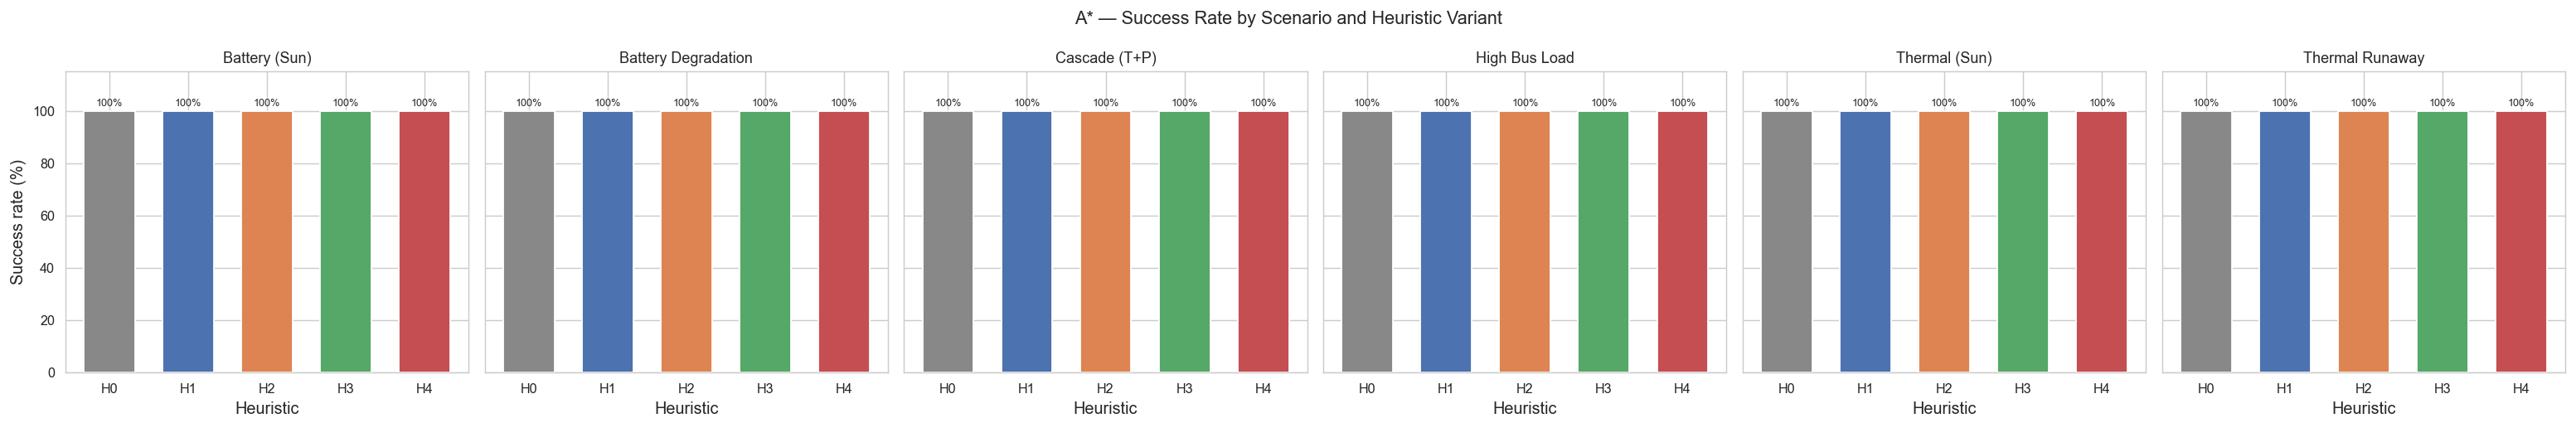

Fig 1 saved


In [4]:
astar_df  = df[df['algorithm'] == 'astar'].copy()
scenarios = sorted(astar_df['scenario_label'].unique())
variants  = ['H0', 'H1', 'H2', 'H3', 'H4']

fig, axes = plt.subplots(1, max(len(scenarios),1), figsize=(4*max(len(scenarios),1), 4), sharey=True)
if len(scenarios) == 1:
    axes = [axes]

for ax, sc_label in zip(axes, scenarios):
    sub   = astar_df[astar_df['scenario_label'] == sc_label]
    rates = [sub[sub['heuristic_variant']==v]['success'].mean()*100 if len(sub[sub['heuristic_variant']==v]) else 0 for v in variants]
    bars  = ax.bar(variants, rates, color=[VARIANT_COLORS.get(v,'#aaa') for v in variants], edgecolor='white', width=0.65)
    ax.set_ylim(0, 115)
    ax.set_title(sc_label, fontsize=10)
    ax.set_xlabel('Heuristic')
    for bar, r in zip(bars, rates):
        if r > 0:
            ax.text(bar.get_x()+bar.get_width()/2, r+1, f'{r:.0f}%', ha='center', va='bottom', fontsize=7)

axes[0].set_ylabel('Success rate (%)')
fig.suptitle('A* — Success Rate by Scenario and Heuristic Variant', fontsize=12)
plt.tight_layout()
Path('../experiments/results').mkdir(parents=True, exist_ok=True)
plt.savefig('../experiments/results/fig1_success_rate.pdf', bbox_inches='tight')
plt.show()
print('Fig 1 saved')

## 4  Fig 2 — Nodes expanded & safety margin per algorithm

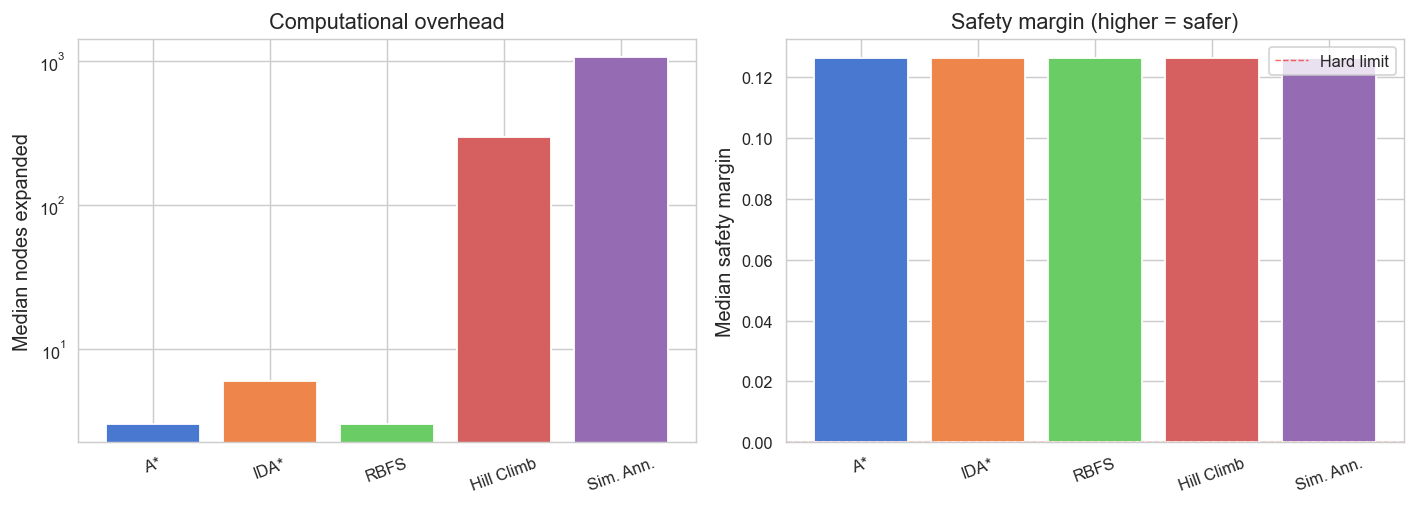

Fig 2 saved


In [5]:
algos_order = ['astar','idastar','rbfs','hill_climbing','simulated_annealing']
algo_labels = [ALGO_LABELS.get(a,a) for a in algos_order]

fig, axes = plt.subplots(1, 2, figsize=(11,4))
pal = sns.color_palette('muted', len(algos_order))

ax = axes[0]
vals = [df[df['algorithm']==a]['nodes_expanded'].median() for a in algos_order]
ax.bar(algo_labels, vals, color=pal, edgecolor='white')
ax.set_ylabel('Median nodes expanded')
ax.set_title('Computational overhead')
ax.set_yscale('log')
ax.tick_params(axis='x', rotation=20)

ax = axes[1]
vals = [df[df['algorithm']==a]['safety_margin'].median() for a in algos_order]
ax.bar(algo_labels, vals, color=pal, edgecolor='white')
ax.axhline(0, color='red', linestyle='--', linewidth=0.8, alpha=0.6, label='Hard limit')
ax.set_ylabel('Median safety margin')
ax.set_title('Safety margin (higher = safer)')
ax.legend()
ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('../experiments/results/fig2_algo_comparison.pdf', bbox_inches='tight')
plt.show()
print('Fig 2 saved')

## 5  Fig 3 — λ ablation on single_thermal A*/H2

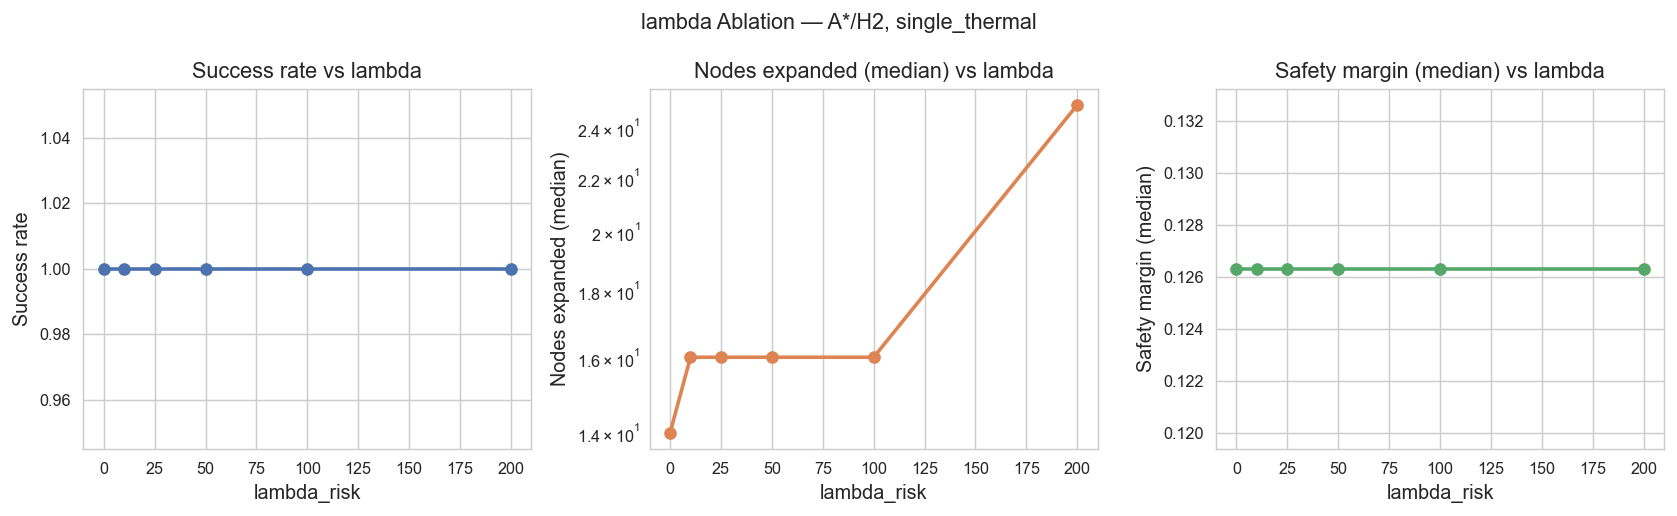

Fig 3 saved


In [6]:
abl = df[(df['algorithm']=='astar') & (df['heuristic_variant']=='H2') & (df['scenario']=='single_thermal')].copy()

if abl.empty:
    print('No lambda-ablation data. Run --sweep-lambda first.')
else:
    lambdas = sorted(abl['lambda_risk'].unique())
    agg = abl.groupby('lambda_risk').agg(
        success=('success','mean'), nodes=('nodes_expanded','median'), margin=('safety_margin','median')
    ).reindex(lambdas)

    fig, axes = plt.subplots(1, 3, figsize=(13,4))
    for ax, col, label, color, logy in zip(axes,
        ['success', 'nodes', 'margin'],
        ['Success rate', 'Nodes expanded (median)', 'Safety margin (median)'],
        ['#4C72B0','#DD8452','#55A868'],
        [False, True, False]):
        ax.plot(lambdas, agg[col].values, 'o-', color=color, linewidth=2, markersize=6)
        ax.set_xlabel('lambda_risk')
        ax.set_ylabel(label)
        ax.set_title(f'{label} vs lambda')
        if logy:
            ax.set_yscale('log')

    fig.suptitle('lambda Ablation — A*/H2, single_thermal', fontsize=12)
    plt.tight_layout()
    plt.savefig('../experiments/results/fig3_lambda_ablation.pdf', bbox_inches='tight')
    plt.show()
    print('Fig 3 saved')

## 6  Fig 4 — Cascade scenario: algorithm comparison

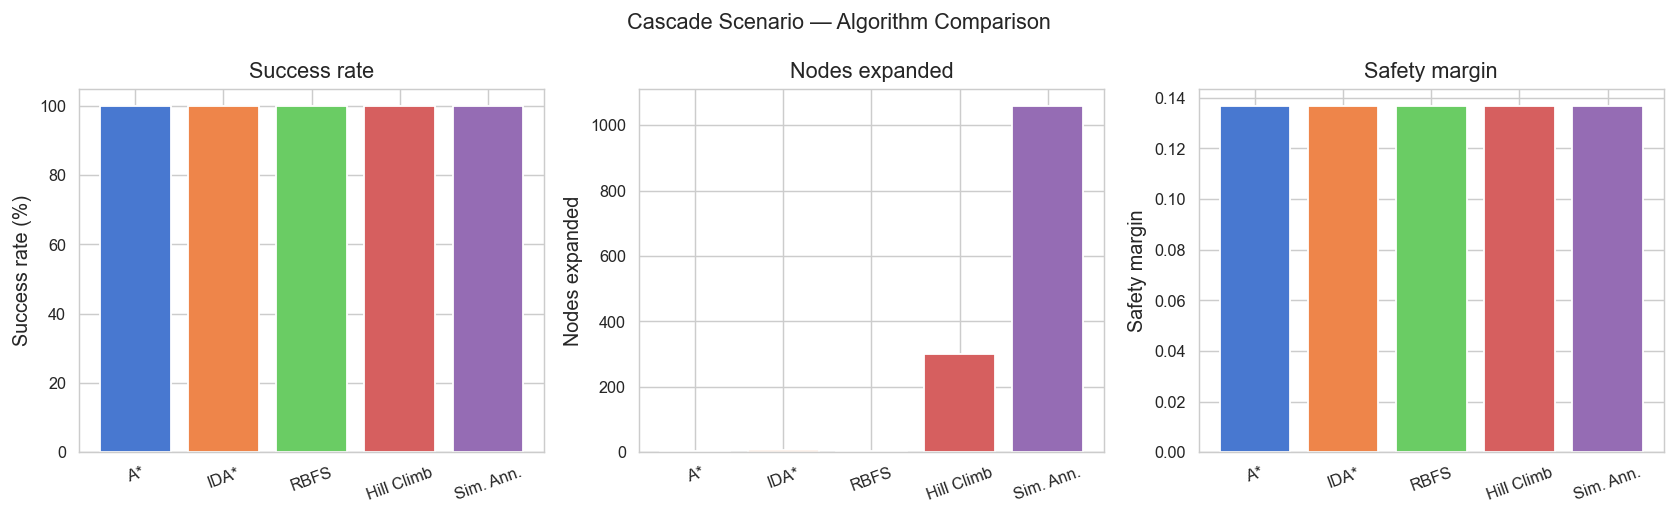

Fig 4 saved


In [7]:
cas = df[df['scenario']=='cascade'].copy()

if cas.empty:
    print('No cascade results.')
else:
    present_algos = [a for a in algos_order if a in cas['algorithm'].unique()]
    pal2 = sns.color_palette('muted', len(present_algos))

    fig, axes = plt.subplots(1, 3, figsize=(13,4))
    for ax, (col, ylabel, pct) in zip(axes, [
        ('success','Success rate',True),
        ('nodes_expanded','Nodes expanded',False),
        ('safety_margin','Safety margin',False)]):
        for algo, color in zip(present_algos, pal2):
            s = cas[cas['algorithm']==algo][col]
            v = s.mean()*100 if pct else s.median()
            ax.bar(ALGO_LABELS.get(algo,algo), v, color=color, edgecolor='white')
        ax.set_ylabel(ylabel + (' (%)' if pct else ''))
        ax.set_title(ylabel)
        ax.tick_params(axis='x', rotation=20)

    fig.suptitle('Cascade Scenario — Algorithm Comparison', fontsize=12)
    plt.tight_layout()
    plt.savefig('../experiments/results/fig4_cascade_comparison.pdf', bbox_inches='tight')
    plt.show()
    print('Fig 4 saved')

## 7  Fig 5 — Heuristic variant deep-dive (2x2 panel)

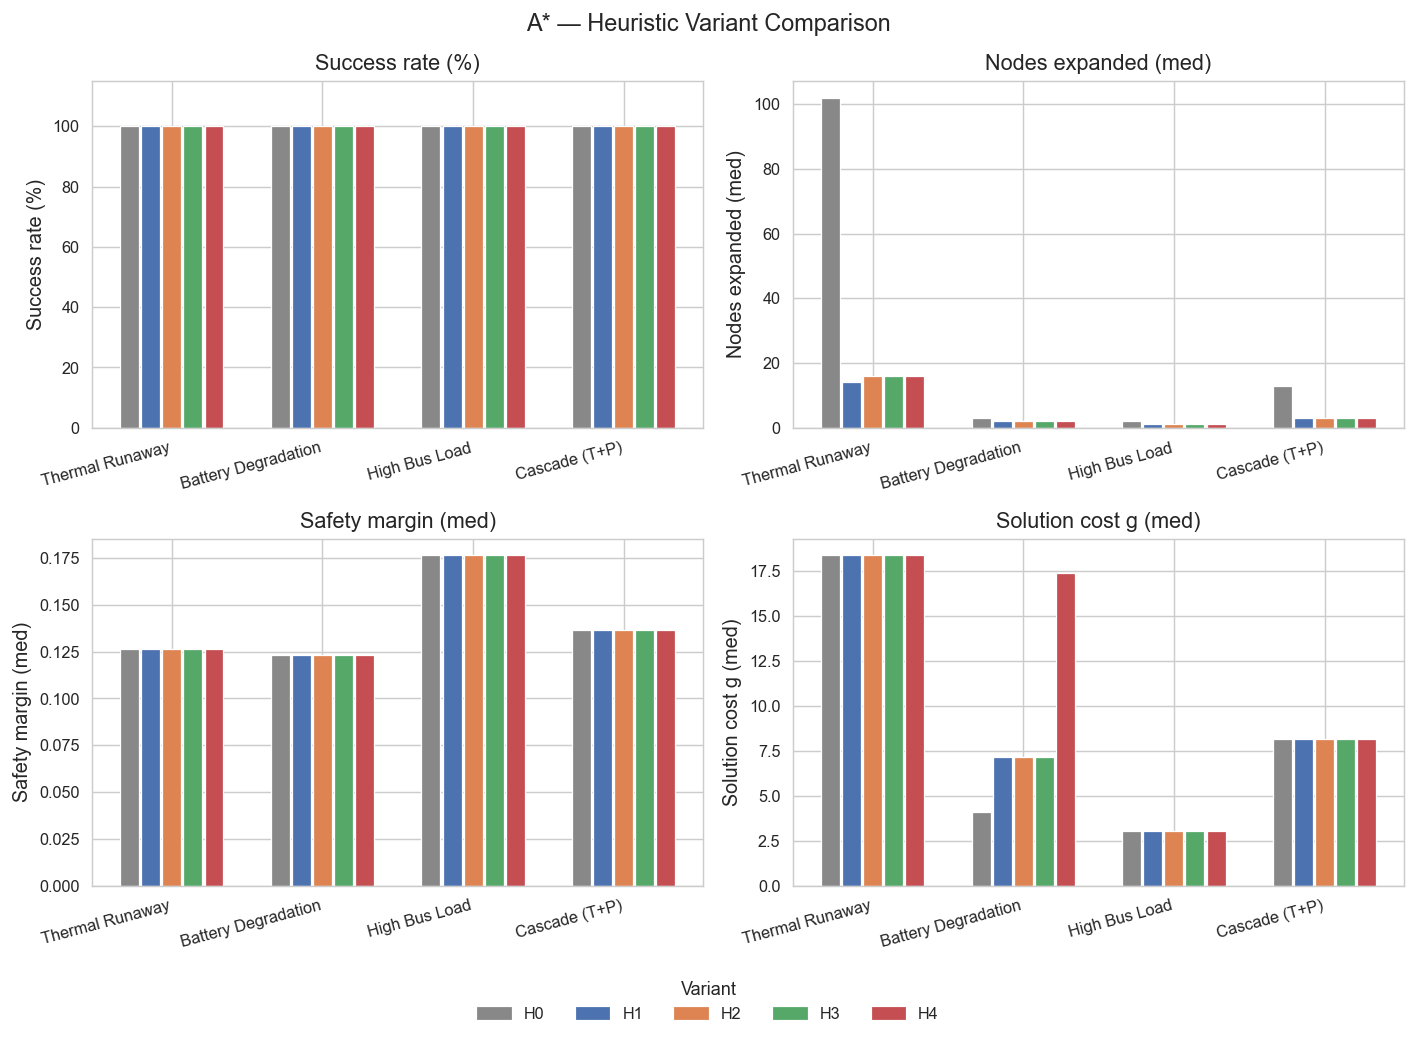

Fig 5 saved


In [8]:
h_df = df[df['algorithm']=='astar'].copy()
v_list = [v for v in ['H0','H1','H2','H3','H4'] if v in h_df['heuristic_variant'].unique()]
sc_list = [s for s in ['single_thermal','single_power','single_load','cascade'] if s in h_df['scenario'].unique()]

fig, axes = plt.subplots(2, 2, figsize=(11,8))
panels = [
    ('success',        'Success rate (%)',      axes[0,0]),
    ('nodes_expanded', 'Nodes expanded (med)', axes[0,1]),
    ('safety_margin',  'Safety margin (med)',  axes[1,0]),
    ('solution_cost',  'Solution cost g (med)',axes[1,1]),
]
x = np.arange(len(sc_list))
width = 0.7 / max(len(v_list),1)

for col, ylabel, ax in panels:
    for i, v in enumerate(v_list):
        vdf = h_df[h_df['heuristic_variant']==v]
        vals = [(vdf[vdf['scenario']==s][col].mean()*100 if col=='success' else vdf[vdf['scenario']==s][col].median()) for s in sc_list]
        ax.bar(x + (i - len(v_list)/2 + 0.5)*width, vals, width=width*0.9,
               color=VARIANT_COLORS.get(v,'#aaa'), label=v, edgecolor='white', linewidth=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels([SCENARIO_LABELS.get(s,s) for s in sc_list], rotation=15, ha='right')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    if col=='success':
        ax.set_ylim(0,115)

handles = [mpatches.Patch(color=VARIANT_COLORS.get(v,'#aaa'), label=v) for v in v_list]
fig.legend(handles=handles, loc='lower center', ncol=len(v_list), title='Variant', frameon=False)
fig.suptitle('A* — Heuristic Variant Comparison', fontsize=13)
plt.tight_layout(rect=[0,0.06,1,1])
plt.savefig('../experiments/results/fig5_variant_comparison.pdf', bbox_inches='tight')
plt.show()
print('Fig 5 saved')

## 8  Fig 6 — Memory: A* vs IDA* vs RBFS

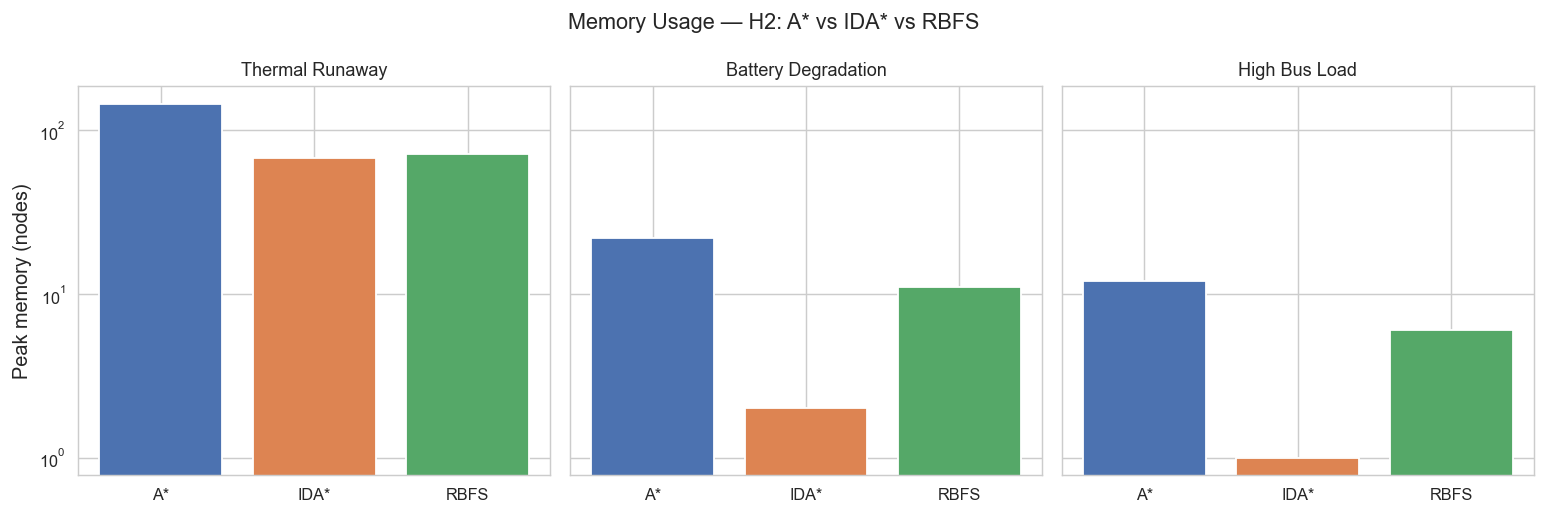

Fig 6 saved


In [9]:
mem_algos = ['astar','idastar','rbfs']
mem_df = df[(df['algorithm'].isin(mem_algos)) & (df['heuristic_variant']=='H2')].copy()

if mem_df.empty:
    print('No data — run sweep first.')
else:
    display_scs = sc_list[:3]
    fig, axes = plt.subplots(1, len(display_scs), figsize=(4*len(display_scs),4), sharey=True)
    if len(display_scs)==1: axes=[axes]
    mem_colors = ['#4C72B0','#DD8452','#55A868']
    for ax, sc in zip(axes, display_scs):
        sub = mem_df[mem_df['scenario']==sc]
        for algo, color in zip(mem_algos, mem_colors):
            adf = sub[sub['algorithm']==algo]['peak_memory_nodes']
            ax.bar(ALGO_LABELS.get(algo,algo), adf.median() if len(adf) else 0, color=color, edgecolor='white')
        ax.set_title(SCENARIO_LABELS.get(sc,sc), fontsize=10)
        ax.set_yscale('log')
    axes[0].set_ylabel('Peak memory (nodes)')
    fig.suptitle('Memory Usage — H2: A* vs IDA* vs RBFS', fontsize=12)
    plt.tight_layout()
    plt.savefig('../experiments/results/fig6_memory_comparison.pdf', bbox_inches='tight')
    plt.show()
    print('Fig 6 saved')

## 9  Fig 7 — Recovery trajectory trace

Scorer: loaded
Success: True  depth: 3  nodes: 16


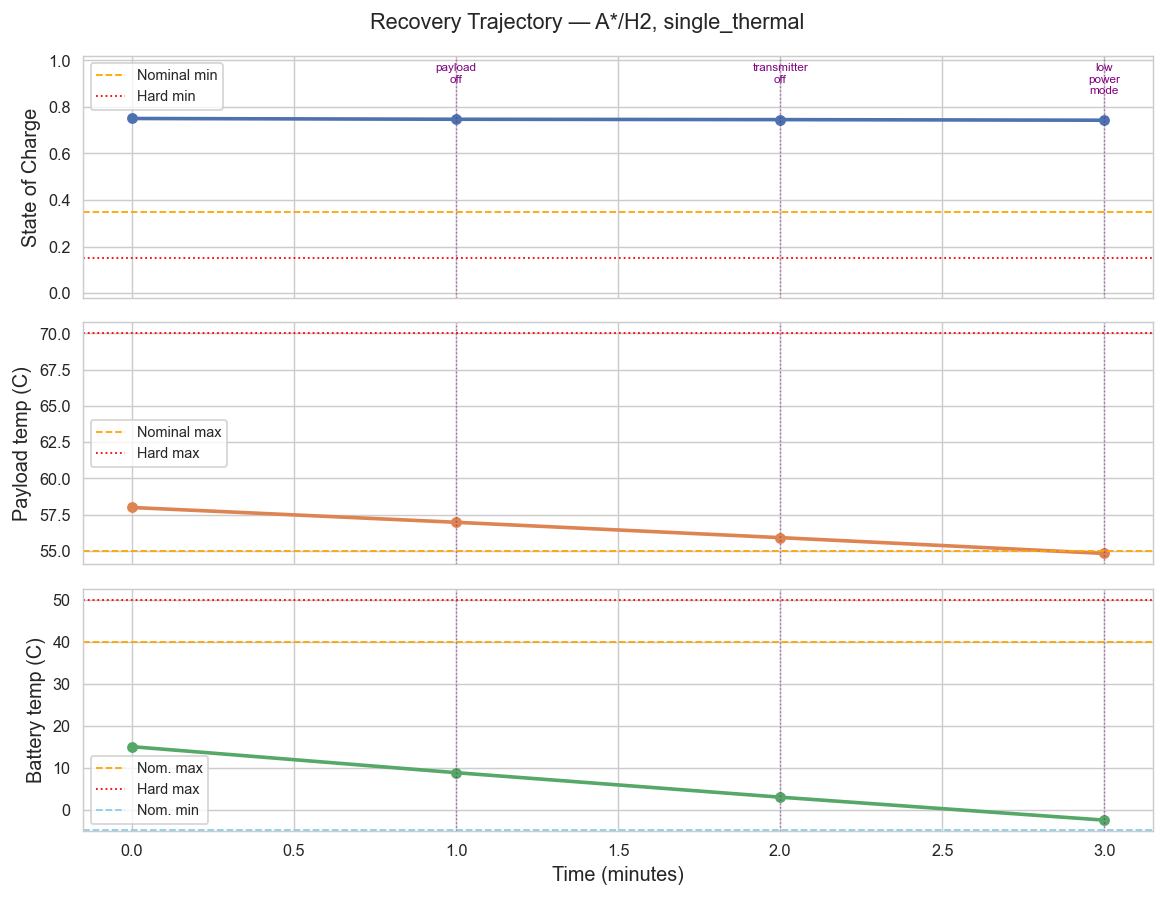

Fig 7 saved


In [10]:
import importlib
import satellite_recovery.simulator.faults as flt
import satellite_recovery.evaluation.scenarios as sc_mod
importlib.reload(flt); importlib.reload(sc_mod)

from satellite_recovery.search.astar import DynamicAStar
from satellite_recovery.anomaly.scorer import BaseScorer

SCENARIOS = sc_mod.SCENARIOS
sc_obj = SCENARIOS['single_thermal']
prob = sc_obj.build_problem()

scorer_path = Path('../experiments/scorers/isolation_forest.joblib')
scorer = BaseScorer.load(str(scorer_path)) if scorer_path.exists() else None
print('Scorer:', 'loaded' if scorer else 'not found (running without)')

algo   = DynamicAStar(budget_nodes=5000, max_depth=20, lambda_risk=50.0, variant='H2')
result = algo.search(prob, scorer, seed=0)
print(f'Success: {result.success}  depth: {result.solution_depth}  nodes: {result.stats.nodes_expanded}')

if result.path:
    states  = [s for s, _ in result.path]
    actions = [a for _, a in result.path]
    times   = np.array([s.time / 60 for s in states])
    p = prob.params

    fig, axes = plt.subplots(3, 1, figsize=(9,7), sharex=True)

    ax = axes[0]
    ax.plot(times, [s.soc for s in states], 'o-', color='#4C72B0', lw=2, ms=5)
    ax.axhline(p.soc_nominal_min, ls='--', color='orange', lw=1, label='Nominal min')
    ax.axhline(p.soc_hard_min,    ls=':',  color='red',    lw=1, label='Hard min')
    ax.set_ylabel('State of Charge')
    ax.legend(fontsize=8)
    ax.set_ylim(-0.02, 1.02)

    ax = axes[1]
    ax.plot(times, [s.temp_payload for s in states], 'o-', color='#DD8452', lw=2, ms=5)
    ax.axhline(p.temp_pay_nominal_max, ls='--', color='orange', lw=1, label='Nominal max')
    ax.axhline(p.temp_pay_hard_max,    ls=':',  color='red',    lw=1, label='Hard max')
    ax.set_ylabel('Payload temp (C)')
    ax.legend(fontsize=8)

    ax = axes[2]
    ax.plot(times, [s.temp_battery for s in states], 'o-', color='#55A868', lw=2, ms=5)
    ax.axhline(p.temp_bat_nominal_max, ls='--', color='orange', lw=1, label='Nom. max')
    ax.axhline(p.temp_bat_hard_max,    ls=':',  color='red',    lw=1, label='Hard max')
    ax.axhline(p.temp_bat_nominal_min, ls='--', color='skyblue',lw=1, label='Nom. min')
    ax.set_ylabel('Battery temp (C)')
    ax.set_xlabel('Time (minutes)')
    ax.legend(fontsize=8)

    for ax in axes:
        for t, a in zip(times, actions):
            if a:
                ax.axvline(t, color='purple', ls=':', lw=0.8, alpha=0.5)
    for t, a in zip(times, actions):
        if a:
            axes[0].text(t, axes[0].get_ylim()[1]*0.97, a.replace('_','\n'),
                         ha='center', va='top', fontsize=6.5, color='purple')

    fig.suptitle('Recovery Trajectory — A*/H2, single_thermal', fontsize=12)
    plt.tight_layout()
    plt.savefig('../experiments/results/fig7_recovery_trace.pdf', bbox_inches='tight')
    plt.show()
    print('Fig 7 saved')

## 10  Fig 8 — Anomaly score distribution

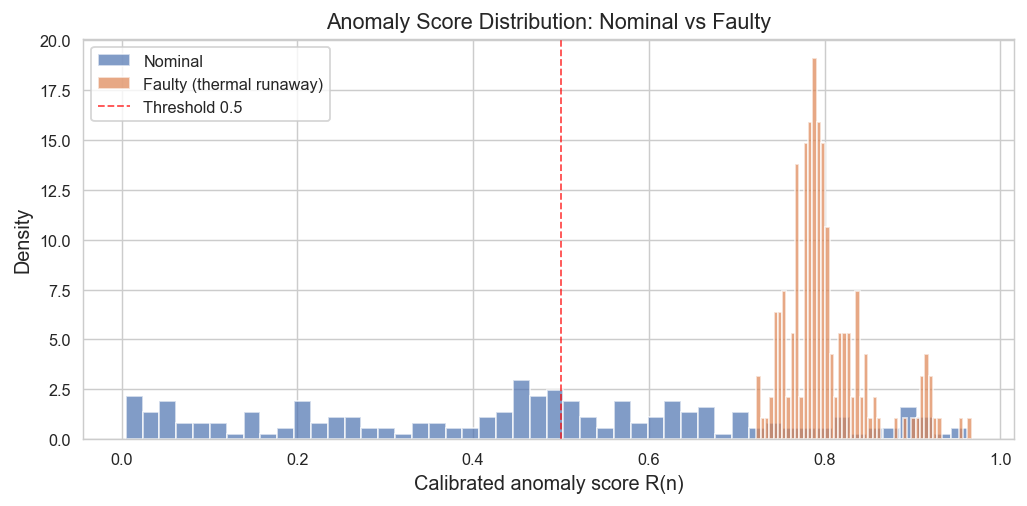

Nominal: mean=0.458  Faulty: mean=0.802


In [11]:
if scorer is None:
    print('Scorer not loaded — skipping.')
else:
    from satellite_recovery.simulator.spacecraft import SpacecraftParams, Simulator
    from satellite_recovery.simulator.orbit import OrbitSchedule
    import satellite_recovery.simulator.faults as flt_mod
    importlib.reload(flt_mod)

    params2 = SpacecraftParams()
    orbit2  = OrbitSchedule(t0=0.0)
    sim2    = Simulator(params2, orbit2)

    nom_state = sim2.make_default_nominal_state()
    nom_traj  = sim2.run_trajectory(nom_state, 200)
    nom_wins  = [nom_traj[max(0,i-9):i+1] for i in range(9, len(nom_traj))]
    nom_sc    = scorer.score_batch(nom_wins)

    fault   = flt_mod.FAULT_REGISTRY['thermal_runaway']
    f_state = flt_mod.inject_fault(nom_state, fault)
    f_traj  = sim2.run_trajectory(f_state, 200)
    f_wins  = [f_traj[max(0,i-9):i+1] for i in range(9, len(f_traj))]
    f_sc    = scorer.score_batch(f_wins)

    fig, ax = plt.subplots(figsize=(8,4))
    ax.hist(nom_sc, bins=50, density=True, alpha=0.7, color='#4C72B0', label='Nominal')
    ax.hist(f_sc,   bins=50, density=True, alpha=0.7, color='#DD8452', label='Faulty (thermal runaway)')
    ax.axvline(0.5, color='red', ls='--', lw=1, alpha=0.7, label='Threshold 0.5')
    ax.set_xlabel('Calibrated anomaly score R(n)')
    ax.set_ylabel('Density')
    ax.set_title('Anomaly Score Distribution: Nominal vs Faulty')
    ax.legend()
    plt.tight_layout()
    plt.savefig('../experiments/results/fig8_score_distribution.pdf', bbox_inches='tight')
    plt.show()
    print(f'Nominal: mean={nom_sc.mean():.3f}  Faulty: mean={f_sc.mean():.3f}')

---
*All figures saved to `experiments/results/fig*.pdf`.*